In [2]:
!pip install -q transformers accelerate tensorflow scikit-learn pandas matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModelForSequenceClassification

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [4]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Reviews.csv")

print(df.head())
print(df.shape)
print(df.columns)

Saving Reviews.csv to Reviews.csv
   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought severa

In [5]:
df = df[['Text', 'Score']]

df.dropna(inplace=True)

df.drop_duplicates(subset=['Text'], inplace=True)

def sentiment(score):

    if score <= 2:
        return 0       # Negative

    elif score == 3:
        return 1       # Neutral

    else:
        return 2       # Positive

df['Sentiment'] = df['Score'].apply(sentiment)

print(df.head())

print(df['Sentiment'].value_counts())

                                                Text  Score  Sentiment
0  I have bought several of the Vitality canned d...      5          2
1  Product arrived labeled as Jumbo Salted Peanut...      1          0
2  This is a confection that has been around a fe...      4          2
3  If you are looking for the secret ingredient i...      2          0
4  Great taffy at a great price.  There was a wid...      5          2
Sentiment
2    306758
0     57067
1     29754
Name: count, dtype: int64


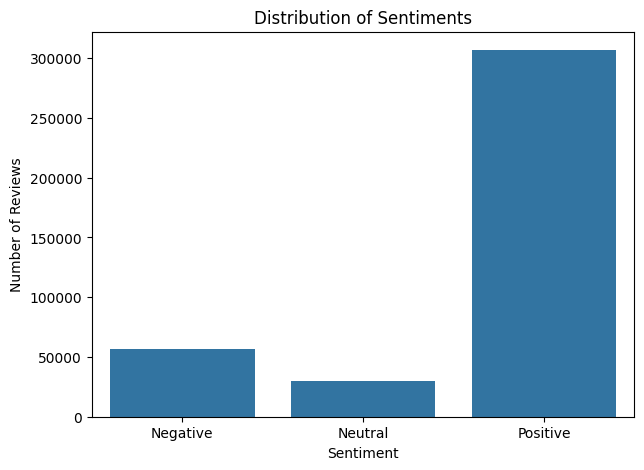

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Sentiment',
    data=df
)

plt.xticks(
    [0, 1, 2],
    ['Negative', 'Neutral', 'Positive']
)

plt.title("Distribution of Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [7]:
df = df.groupby('Sentiment', group_keys=False).apply(
    lambda x: x.sample(
        min(len(x), 10000),
        random_state=42
    )
).reset_index(drop=True)

X = df['Text'].astype(str)
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24000
Testing samples: 6000


/tmp/ipykernel_3852/2883089299.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('Sentiment', group_keys=False).apply(


In [8]:
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [9]:
lstm_model = Sequential()

lstm_model.add(
    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=max_length
    )
)

lstm_model.add(
    LSTM(64)
)

lstm_model.add(
    Dropout(0.3)
)

lstm_model.add(
    Dense(32, activation='relu')
)

lstm_model.add(
    Dense(3, activation='softmax')
)

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

lstm_time = time.time() - start_time

print("LSTM Training Time:", lstm_time)

Epoch 1/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.3670 - loss: 1.0927 - val_accuracy: 0.3844 - val_loss: 1.0906
Epoch 2/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4289 - loss: 1.0585 - val_accuracy: 0.4475 - val_loss: 1.0586
Epoch 3/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4545 - loss: 1.0457 - val_accuracy: 0.4004 - val_loss: 1.0806
LSTM Training Time: 17.94625186920166


In [11]:
lstm_predictions = lstm_model.predict(X_test_pad)

lstm_predictions = np.argmax(
    lstm_predictions,
    axis=1
)

lstm_accuracy = accuracy_score(
    y_test,
    lstm_predictions
)

print("LSTM Accuracy:", lstm_accuracy)

print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=[
            'Negative',
            'Neutral',
            'Positive'
        ],
        zero_division=0
    )
)

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
LSTM Accuracy: 0.38133333333333336
              precision    recall  f1-score   support

    Negative       0.41      0.11      0.17      2000
     Neutral       0.42      0.23      0.30      2000
    Positive       0.37      0.80      0.50      2000

    accuracy                           0.38      6000
   macro avg       0.40      0.38      0.33      6000
weighted avg       0.40      0.38      0.33      6000



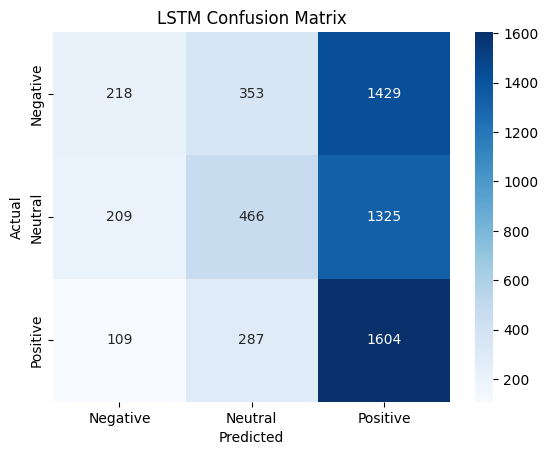

In [12]:
cm = confusion_matrix(
    y_test,
    lstm_predictions
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [13]:
model_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

print("BERT model loaded successfully!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!


In [14]:
class ReviewDataset(Dataset):

    def __init__(self, texts, labels):

        self.texts = list(texts)
        self.labels = list(labels)

    def __len__(self):

        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts[index]

        label = int(self.labels[index])

        encoding = bert_tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=128,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }


# Create datasets
train_dataset = ReviewDataset(
    X_train,
    y_train
)

test_dataset = ReviewDataset(
    X_test,
    y_test
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16
)

In [15]:
# Use GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

bert_model.to(device)

# Optimizer
optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

# Enable mixed precision on GPU
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

# Reduce training time
epochs = 1

start_time = time.time()

for epoch in range(epochs):

    bert_model.train()

    total_loss = 0

    # Train on only 300 batches
    for batch_no, batch in enumerate(train_loader):

        if batch_no >= 300:
            break

        input_ids = batch['input_ids'].to(device)

        attention_mask = batch['attention_mask'].to(device)

        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        # Mixed precision
        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):

            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        total_loss += loss.item()

    average_loss = total_loss / min(
        len(train_loader), 300
    )

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

bert_time = time.time() - start_time

print("BERT Training Time:", bert_time)

Using device: cuda
Epoch 1/1, Loss: 0.7779
BERT Training Time: 42.03785681724548


In [16]:
bert_model.eval()

bert_predictions = []
actual_labels = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch['input_ids'].to(device)

        attention_mask = batch['attention_mask'].to(device)

        labels = batch['labels'].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_predictions.extend(
            predictions.cpu().numpy()
        )

        actual_labels.extend(
            labels.cpu().numpy()
        )


bert_accuracy = accuracy_score(
    actual_labels,
    bert_predictions
)

print("BERT Accuracy:", bert_accuracy)

print(
    classification_report(
        actual_labels,
        bert_predictions,
        target_names=[
            'Negative',
            'Neutral',
            'Positive'
        ],
        zero_division=0
    )
)

BERT Accuracy: 0.719
              precision    recall  f1-score   support

    Negative       0.71      0.76      0.73      2000
     Neutral       0.65      0.55      0.60      2000
    Positive       0.78      0.85      0.81      2000

    accuracy                           0.72      6000
   macro avg       0.71      0.72      0.71      6000
weighted avg       0.71      0.72      0.71      6000



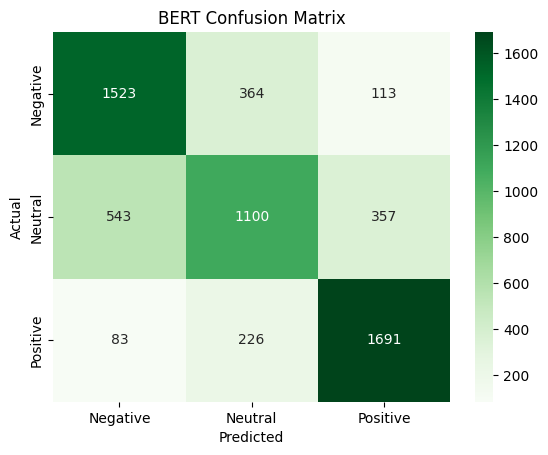

In [17]:
cm = confusion_matrix(
    actual_labels,
    bert_predictions
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("BERT Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

  Model  Accuracy  Training Time (seconds)
0  LSTM  0.381333                17.946252
1  BERT  0.719000                42.037857


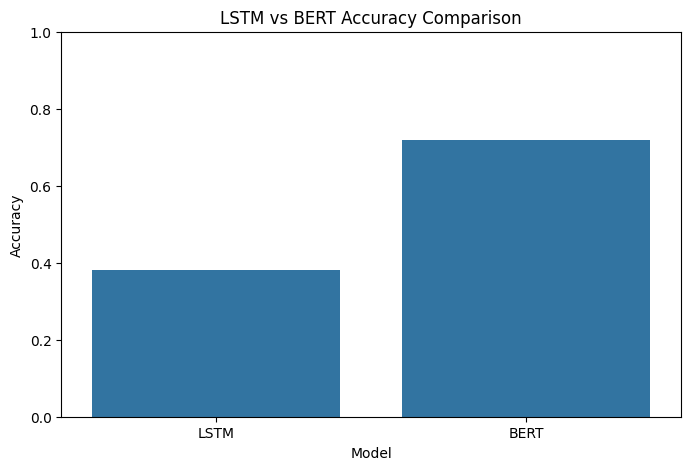

In [18]:
# Create comparison table
results = pd.DataFrame({
    'Model': ['LSTM', 'BERT'],

    'Accuracy': [
        lstm_accuracy,
        bert_accuracy
    ],

    'Training Time (seconds)': [
        lstm_time,
        bert_time
    ]
})

print(results)

# Display comparison graph
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("LSTM vs BERT Accuracy Comparison")
plt.ylim(0, 1)

plt.show()

In [19]:
lstm_f1 = f1_score(
    y_test,
    lstm_predictions,
    average='weighted'
)

bert_f1 = f1_score(
    actual_labels,
    bert_predictions,
    average='weighted'
)

comparison = pd.DataFrame({
    'Model': ['LSTM', 'BERT'],
    'Accuracy': [lstm_accuracy, bert_accuracy],
    'F1 Score': [lstm_f1, bert_f1],
    'Training Time': [lstm_time, bert_time]
})

print("\nFINAL MODEL COMPARISON")
print(comparison)


FINAL MODEL COMPARISON
  Model  Accuracy  F1 Score  Training Time
0  LSTM  0.381333  0.325517      17.946252
1  BERT  0.719000  0.714381      42.037857


In [20]:
# Save LSTM model
lstm_model.save("lstm_sentiment_model.keras")

# Save BERT model
bert_model.save_pretrained("bert_sentiment_model")

bert_tokenizer.save_pretrained("bert_sentiment_model")

print("Both models saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Both models saved successfully!


In [21]:
def predict_sentiment(review):

    bert_model.eval()

    inputs = bert_tokenizer(
        review,
        return_tensors='pt',
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = bert_model(**inputs)

        prediction = torch.argmax(
            outputs.logits,
            dim=1
        ).item()

    labels = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }

    return labels[prediction]


# Test examples
print(
    predict_sentiment(
        "This product is amazing. I really love it!"
    )
)

print(
    predict_sentiment(
        "The product is okay, nothing special."
    )
)

print(
    predict_sentiment(
        "Very poor quality. I am disappointed."
    )
)

Positive
Neutral
Negative
